# Human influence in Rural Wildfires ignitions

## Group: 02
### Name(s) & ID(s) of Group Members:
- Benedita Barreto da Costa Gonçalves - 202205903
- Isabela Moreira Merelles - 202602764
- Maria Leonor Soares Carvalho - 202307522
- Mariana Vale de Oliveira Coelho de Pinho - 202306234

## Table of Contents

1. [Research Question](#1-research-question)
2. [Collect Data](#2-collect-data)
3. [Explore & Draw Inferences](#3-explore-and-draw-inferences)
4. [Formulate Conclusions](#4-formulate-conclusions)
5. [Look Back and Ahead](#5-look-back-and-ahead)

---

## 1) Research Question

How did initial response times and burnt areas change before and after 2017, and how are these two variables associated across four Portuguese municipalities?

### Secondary Research Questions:

1. Was the change in the proportion of negligent causes concentrated in the critical summer period, or did it also affect the traditional burning months (autumn/winter)?

    Difference in proportion (Variables to use: cause_type, period, season_risk_period). Test: Z test


2. Did the reduction in negligent wildfire occurrences translate into a significantly lower mean number of daily ignitions on weekends compared to weekdays?

    Mean comparison (Variables to use: Daily_Ignitions_Count, Day_Type, Period). Test: t-test


3. Do final burnt areas differ significantly across the four municipalities under study?

    ANOVA (Variables: Log_Total_Burnt_Area, Municipality). Test: One-way ANOVA.


4. Did the disparity in final burnt area between intentional and negligent causes narrow in the post-2017 period in the municipalities under study?

    ANOVA (Variables to use: Log_Total_Burnt_Area, Cause_Type_Period). Test: Two-way ANOVA 


---

## 2) Collect data

### Dataset Source

The dataset used in this project was sourced from the Institute for Nature Conservation and Forests (ICNF), specifically the wildfire statistics published under the Information Management section of [their website](https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas). This dataset contains data on human influenced wildfire ignitions from 2001 until 2025. The records are split across three ICNF files (2001-2010, 2011-2020 and 2021-2025), and were combined into a single dataset before analysis.

The raw file contains 40 columns covering fire identifiers, location, timestamps, burnt area by land cover, fire weather indices, and cause classification. Only a subset of these columns was used in the analysis, and several variables were derived from them. The full mapping is described below so that the variables can be reproduced from the raw file.

### Dataset Details


#### Variables: 

##### Qualitative Variables

- **Cause_Type**: Intentional vs. Negligent. Derived from the cause classification columns (`TipoCausa`, `GrupoCausa`, `CodCausa`), keeping only validated human causes. Fires with an unclassified or unknown cause were excluded.

- **Period**: Pre-2017 (2001–2016) vs. Post-2017 (2018–2025). Derived from `Ano`. In practice, the law was only implemented in 2021, so the post-2017 group mixes pre-law and post-law years (see limitations).

- **Municipality**: Chaves, Montalegre, Ourém, Tomar. Taken from `Concelho`.

- **Season_Risk_Period**: Critical Period vs. Non-Critical Period. Derived from `Mes` and `Dia`, with the critical period defined as 1 June to 30 September.

- **Day_Type**: Weekend vs. Weekday. Derived from the fire date (`Ano`, `Mes`, `Dia`), with Saturday and Sunday classified as weekend.

- **Cause_Type_Period**: Combined factor of `Cause_Type` and `Period`, used for the two-way ANOVA in Q4.

##### Quantitative Variables

- **Daily_Ignitions_Count**: Number of ignitions per municipality per day, computed by counting `Codigo_SGIF` grouped by `date` and `municipality`.

- **Total_Burnt_Area**: Total surface burnt per occurrence, in hectares, from `AreaTotal_ha`.

- **Initial_Response_Time**: Time in minutes between `DataHoraAlerta` and `DataHora_PrimeiraIntervencao`.

- **Fire_Duration**: Total duration from fire alert to final extinction, in hours, from `Duracao_Horas`.

### Data preparation

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

In [2]:
#Loading the data
cols_necessarias = [
    'Ano', 'Mes', 'Dia', 'Hora', 'AreaTotal_ha', 'Duracao_Horas',
    'DataHoraAlerta', 'DataHora_PrimeiraIntervencao', 'DataHora_Extincao',
    'Concelho', 'TipoCausa', 'Codigo_SGIF'
]

df1 = pd.read_excel(raw / "Registos_Incendios_SGIF_2021_2025.xlsx", usecols=cols_necessarias)
df2 = pd.read_excel(raw / "Registos_Incendios_SGIF_2011_2020.xlsx", usecols=cols_necessarias)
df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=cols_necessarias)

# confirm the raw files share the same schema
print("df1 vs df2:", df1.columns.equals(df2.columns))
print("df2 vs df3:", df2.columns.equals(df3.columns))

df1 vs df2: True
df2 vs df3: True


Before deriving variables, the sample size was checked by municipality and year to confirm that all four municipalities are represented across the full period.

In [3]:
# Concatenar os 3 ficheiros (2001 a 2025)
df = pd.concat([df1, df2, df3], ignore_index=True)

concelhos = ["Chaves", "Ourém", "Montalegre", "Tomar"]

# Filtrar pelos 4 concelhos e pela janela completa de 2001 a 2025
df_final = df[df["Concelho"].isin(concelhos)].copy()
df_final = df_final[df_final["Ano"].between(2001, 2025)].copy()

print(df_final["Concelho"].value_counts())
print(pd.crosstab(df_final["Concelho"], df_final["Ano"], margins=True))

Concelho
Montalegre    5635
Chaves        3914
Ourém         2691
Tomar         2280
Name: count, dtype: int64
Ano         2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  ...  \
Concelho                                                                ...   
Chaves       259   307   127   188   326   167   130   139   308   127  ...   
Montalegre   262   283   177   194   390   147   238   149   475   177  ...   
Ourém        118   159   116   166   293   188   136   144    99    97  ...   
Tomar         58   115    86   166   186   125   130   108   110    95  ...   
All          697   864   506   714  1195   627   634   540   992   496  ...   

Ano         2017  2018  2019  2020  2021  2022  2023  2024  2025    All  
Concelho                                                                 
Chaves       132    67    66    73    46   105    36    68    94   3914  
Montalegre   314   119   168   134   191   192   117    94   131   5635  
Ourém         96    82    63    97    6

In [4]:
# quantitative variables:

#Initial_Response_Time
for col in ["DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao"]:
  df_final[col] = pd.to_datetime(df_final[col], errors="coerce")

df_final["Initial_Response_Time"] = (
    df_final["DataHora_PrimeiraIntervencao"] - df_final["DataHoraAlerta"]
).dt.total_seconds() / 60

#Fire_Duration
df_final["Fire_Duration"] = df_final["Duracao_Horas"]

#Total_Burnt_Area
df_final["Total_Burnt_Area"] = df_final["AreaTotal_ha"]

# Escala logarítmica para cumprir os pressupostos das ANOVAs
df_final["Log_Total_Burnt_Area"] = np.log10(df_final["Total_Burnt_Area"] + 0.001)

In [5]:
#qualitative variables:

#Period
df_final["Period"] = np.where(df_final["Ano"] <= 2016, "Pre-2017",
                       np.where(df_final["Ano"] >= 2018, "Post-2017", "Transition"))

#Season_Risk_Period
df_final["Season_Risk_Period"] = np.where(
    df_final["Mes"].isin([6, 7, 8, 9]),
    "Critical", "Non-Critical"
)

#Day_Type
df_final["Day_Type"] = np.where(
    df_final["DataHoraAlerta"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

In [6]:
# 1. Mapear apenas causas humanas apuradas
cause_map = {
    "Negligente": "Negligent",
    "Intencional": "Intentional",
}

df_final["Cause_Type"] = df_final["TipoCausa"].map(cause_map)

df_final["Cause_Type_Period"] = np.where(
    df_final["Cause_Type"].isna(),
    np.nan,
    df_final["Cause_Type"].astype(str) + "_" + df_final["Period"].astype(str),
)

# 2. Contagem diária de ignições negligentes (excluindo 2017) para a Q2
df_final["Date"] = df_final["DataHoraAlerta"].dt.date

df_neg = df_final[
    (df_final["Cause_Type"] == "Negligent")
    & (df_final["Period"] != "Transition")
].copy()

daily = (
    df_neg.groupby(["Concelho", "Date", "Period"])
    .size()
    .reset_index(name="Daily_Ignitions_Count")
)

daily["Day_Type"] = np.where(
    pd.to_datetime(daily["Date"]).dt.dayofweek >= 5, "Weekend", "Weekday"
)

In [7]:
# Count missing values in each column
print(f"\nNumber of missing values for each column/ feature:")
print(df_final.isnull().sum())


Number of missing values for each column/ feature:
Codigo_SGIF                        0
Ano                                0
Mes                                0
Dia                                0
Hora                               0
AreaTotal_ha                       0
DataHoraAlerta                     0
DataHora_PrimeiraIntervencao    5583
DataHora_Extincao                 43
Duracao_Horas                     43
Concelho                           0
TipoCausa                       6043
Initial_Response_Time           5583
Fire_Duration                     43
Total_Burnt_Area                   0
Log_Total_Burnt_Area               0
Period                             0
Season_Risk_Period                 0
Day_Type                           0
Cause_Type                      7357
Cause_Type_Period               7357
Date                               0
dtype: int64


In [8]:
df_final.describe()

,Ano,Mes,Dia,Hora,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,Initial_Response_Time,Fire_Duration,Total_Burnt_Area,Log_Total_Burnt_Area
count,14520.000000,14520.000000,14520.000000,14520.000000,14520.000000,14520,8937,14477,14477.000000,8937.000000,14477.000000,14520.000000,14520.000000
mean,2011.001446,6.891116,15.793595,14.687190,9.087475,2011-07-14 14:38:06.070247936,2015-08-30 20:28:02.517623296,2011-07-11 13:07:50.770463488,2.433111,18.117153,2.433111,9.087475,-0.772434
min,2001.000000,1.000000,1.000000,0.000000,0.000000,2001-02-18 20:45:00,2008-01-20 17:20:00,2001-02-18 23:05:00,0.000000,0.000000,0.000000,0.000000,-3.000000
25%,2005.000000,5.000000,8.000000,12.000000,0.010000,2005-08-25 18:52:30,2011-09-25 13:12:00,2005-08-25 14:57:00,0.616667,9.000000,0.616667,0.010000,-1.958607
50%,2010.000000,8.000000,16.000000,15.000000,0.200000,2010-10-28 16:55:00,2015-04-03 21:30:00,2010-10-18 17:58:00,1.250000,14.000000,1.250000,0.200000,-0.696804
75%,2016.000000,9.000000,23.000000,18.000000,1.130000,2016-09-11 15:47:45,2019-03-26 18:40:00,2016-09-11 15:38:00,2.533333,20.000000,2.533333,1.130000,0.053463
max,2025.000000,12.000000,31.000000,23.000000,6379.000000,2025-11-04 18:49:00,2025-11-04 19:10:00,2025-11-04 19:24:00,244.550000,1456.000000,244.550000,6379.000000,3.804753
std,6.668413,2.635995,8.666318,5.363572,116.325010,NaN,NaN,NaN,6.112195,30.905899,6.112195,116.325010,1.203978


Saving processed data to be used for statistics

In [9]:
df_final.to_excel(processed / "wildfires_processed.xlsx", index=False)
daily.to_excel(processed / "daily_ignitions.xlsx", index=False)

Per question dataset

In [10]:
# Q1: Negligente vs Intencional, Pré vs Pós, Crítico vs Não-Crítico (Z-test)
q1 = df_final[
    (df_final["Cause_Type"].notna()) & (df_final["Period"] != "Transition")
].copy()
q1.to_excel(processed / "q1_cause_period_season.xlsx", index=False)

# Q2: Ignições diárias de causas negligentes, Weekend vs Weekday (t-test)
q2 = daily.dropna(subset=["Date", "Daily_Ignitions_Count"]).copy()
q2.to_excel(processed / "q2_daily_ignitions.xlsx", index=False)

# Q3: Área ardida por Concelho (One-way ANOVA)
q3 = df_final[
    (df_final["Total_Burnt_Area"].notna())
    & (df_final["Period"] != "Transition")
].copy()
q3.to_excel(processed / "q3_burnt_area_municipality.xlsx", index=False)

# Q4: Área ardida por Cause_Type e Period (Two-way ANOVA)
q4 = df_final[
    (df_final["Cause_Type"].notna())
    & (df_final["Period"] != "Transition")
    & (df_final["Total_Burnt_Area"].notna())
].copy()
q4.to_excel(processed / "q4_burnt_area_cause_period.xlsx", index=False)

#### Missing values

| Question | Variables used | rows dropped where |
|---|---|---|
| Q1 | `Cause_Type`, `Period`, `Season_Risk_Period` | `Cause_Type` is missing or `Period == 'Transition'` (2017) |
| Q2 | `Daily_Ignitions_Count`, `Day_Type`, `Period` | Non-negligent causes, date is missing, or `Period == 'Transition'` |
| Q3 | `Log_Total_Burnt_Area`, `Municipality` | `Total_Burnt_Area` is missing or `Period == 'Transition'` |
| Q4 | `Log_Total_Burnt_Area`, `Cause_Type`, `Period` | `Cause_Type` or `Total_Burnt_Area` is missing, or `Period == 'Transition'` |

In [11]:
log = pd.DataFrame({
    "dataset": ["pooled", "q1", "q2", "q3", "q4"],
    "n_rows": [len(df_final), len(q1), len(q2), len(q3), len(q4)],
    "exclusion": [
        "Initial 4-municipality cohort (2001-2025)",
        "Missing Cause_Type and Transition year (2017) excluded",
        "Negligent daily counts (2017 excluded)",
        "Missing Burnt Area and 2017 excluded",
        "Missing Cause_Type, Burnt Area, and 2017 excluded",
    ],
})
log.to_excel(processed / "sample_sizes.xlsx", index=False)
log

,dataset,n_rows,exclusion
0,pooled,14520,Initial 4-municipality cohort (2001-2025)
1,q1,6519,Missing Cause_Type and Transition year (2017) ...
2,q2,2897,Negligent daily counts (2017 excluded)
3,q3,13816,Missing Burnt Area and 2017 excluded
4,q4,6519,"Missing Cause_Type, Burnt Area, and 2017 excluded"


---

## 3) Explore and draw inferences

### Changes in Negligent Causes (Q1)

In this first phase, we focused on Q1: testing whether the change in the proportion of negligent causes was concentrated in the critical summer period or if it also affected autumn and winter burning months.

### Checking count of data

In [12]:
q1_counts = pd.crosstab(
    [q1["Period"], q1["Season_Risk_Period"]],
    q1["Cause_Type"],
    margins=True
)
q1_counts

Cause_Type                    Intentional  Negligent   All
Period    Season_Risk_Period                              
Post-2017 Critical                    639        576  1215
          Non-Critical                150       1120  1270
Pre-2017  Critical                   1120       1411  2531
          Non-Critical                261       1242  1503
All                                  2170       4349  6519

The total sample for Q1 consists of 6,519 fires due to human cause.

All four combinations have more than 1,200 observations. This means the sample is large enough to trust the Z-test on proportions, and we do not need to worry about small-cell bias.

In the critical period, the counts show intentional fires dropped (from 1,120 to 639), but negligent fires dropped evenmore (from 1,411 to 576).

#### Checking proportion of dataset

In [13]:
q1_props = (
    q1.groupby(["Period", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)
q1_props

,Period,Season_Risk_Period,negligent_share
0,Post-2017,Critical,0.474074
1,Post-2017,Non-Critical,0.881890
2,Pre-2017,Critical,0.557487
3,Pre-2017,Non-Critical,0.826347


In the Critical period, negligent ignitions dropped from 55.7% to 47.4% post-2017. 

In the Non-Critical period, the negligent share actually went up from 82.6% to 88.2%. This is because the counts show that intentional fires in this season fell (261 down to 150), while negligent fires stayed relatively stable (1,242 down to 1,120). Because intentional fires dropped faster than negligent ones, the overall proportion of negligent fires went up.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
%config InlineBackend.figure_format = "retina"
plt.style.use("seaborn-v0_8")

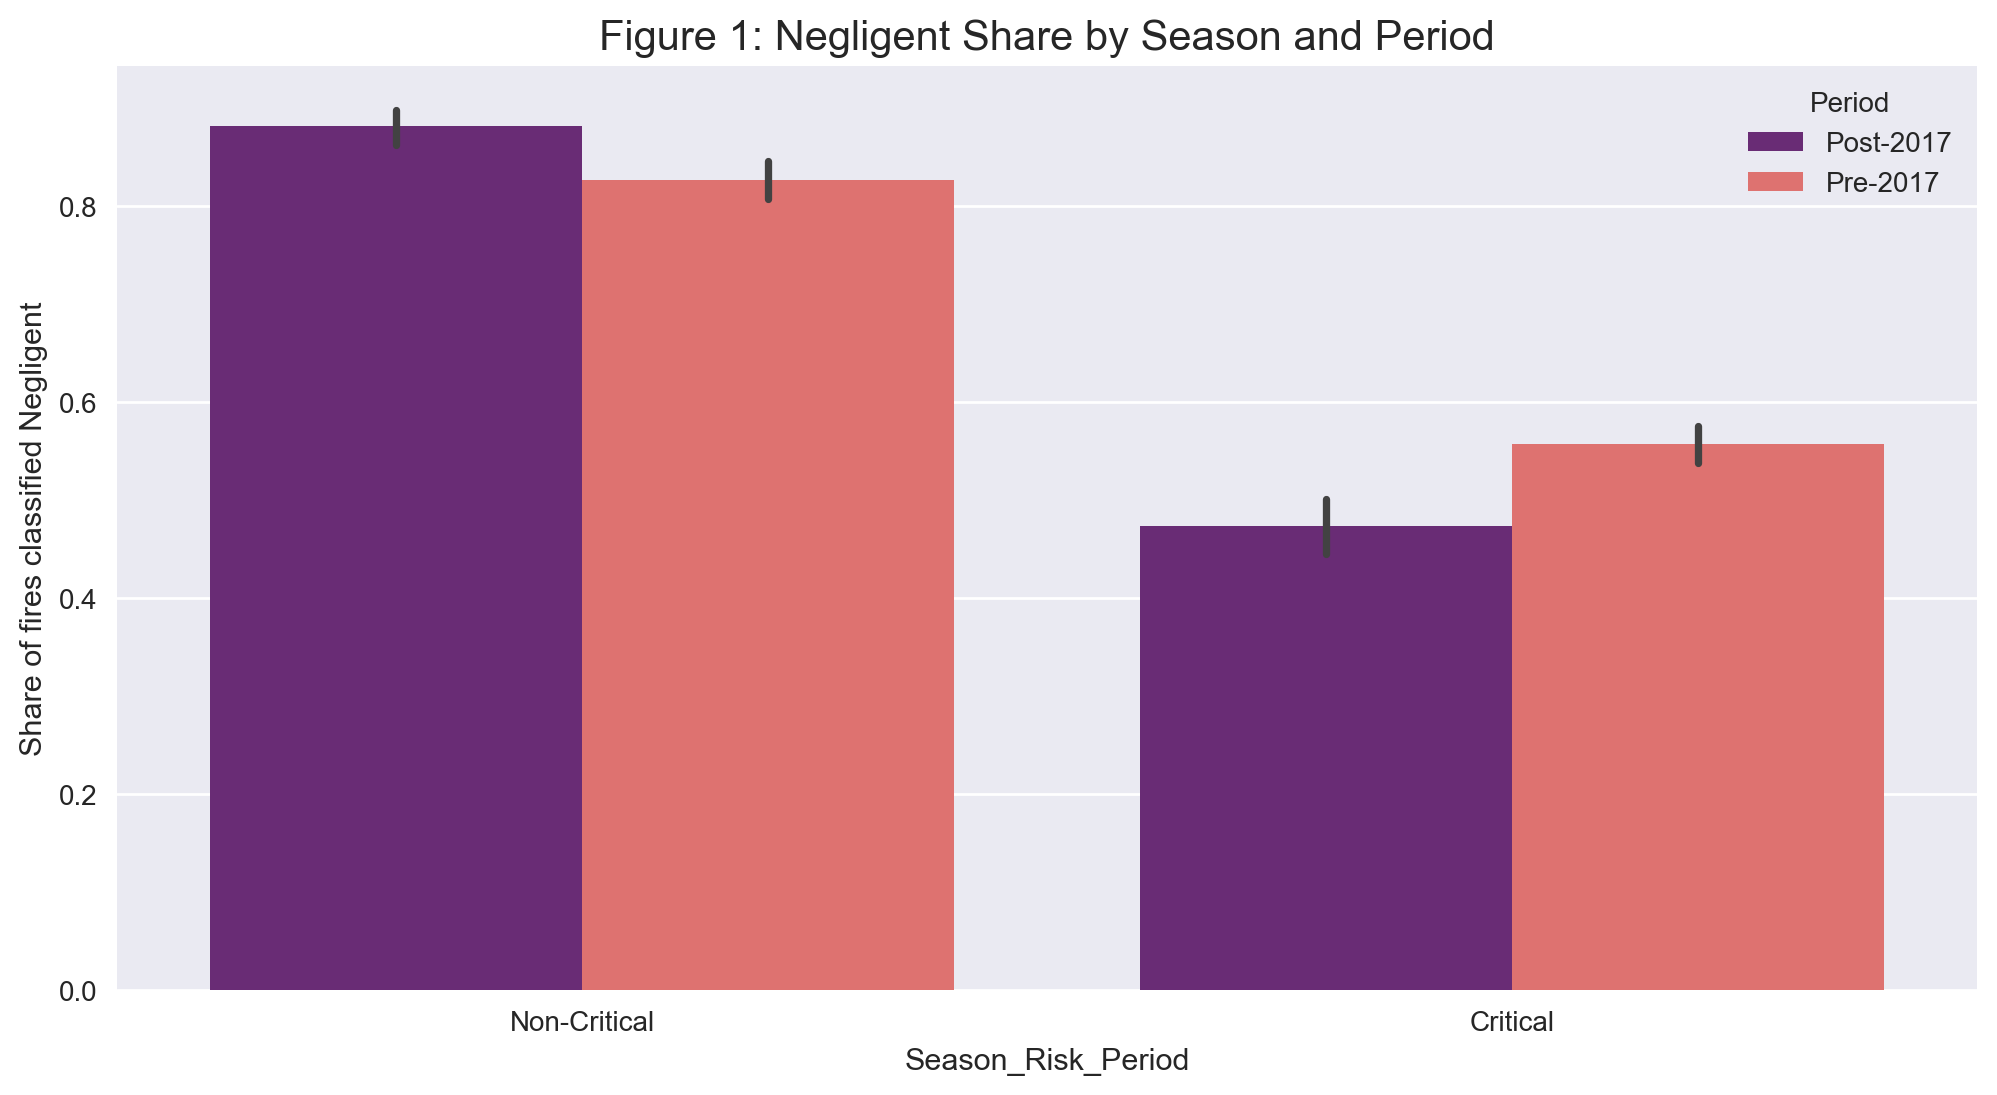

In [15]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=q1, x="Season_Risk_Period", y=(q1["Cause_Type"] == "Negligent").astype(int),
    hue="Period", palette="magma", errorbar="ci"
)
plt.title("Figure 1: Negligent Share by Season and Period", fontsize=15)
plt.ylabel("Share of fires classified Negligent")
plt.show()

Figure 1 shows the change in the proportion of negligent fires between the pre-2017 and post-2017 periods, split by season. 

The decline in fires seem to happen mainly in the **Critical** period. The error bars do not overlap, meaning this drop is likely statistically significant.

In the **Non-Critical** period, the share remains very high in both periods. The slight increase is small and the error bars overlap, suggesting there is no real change.

#### Checking negligence over time

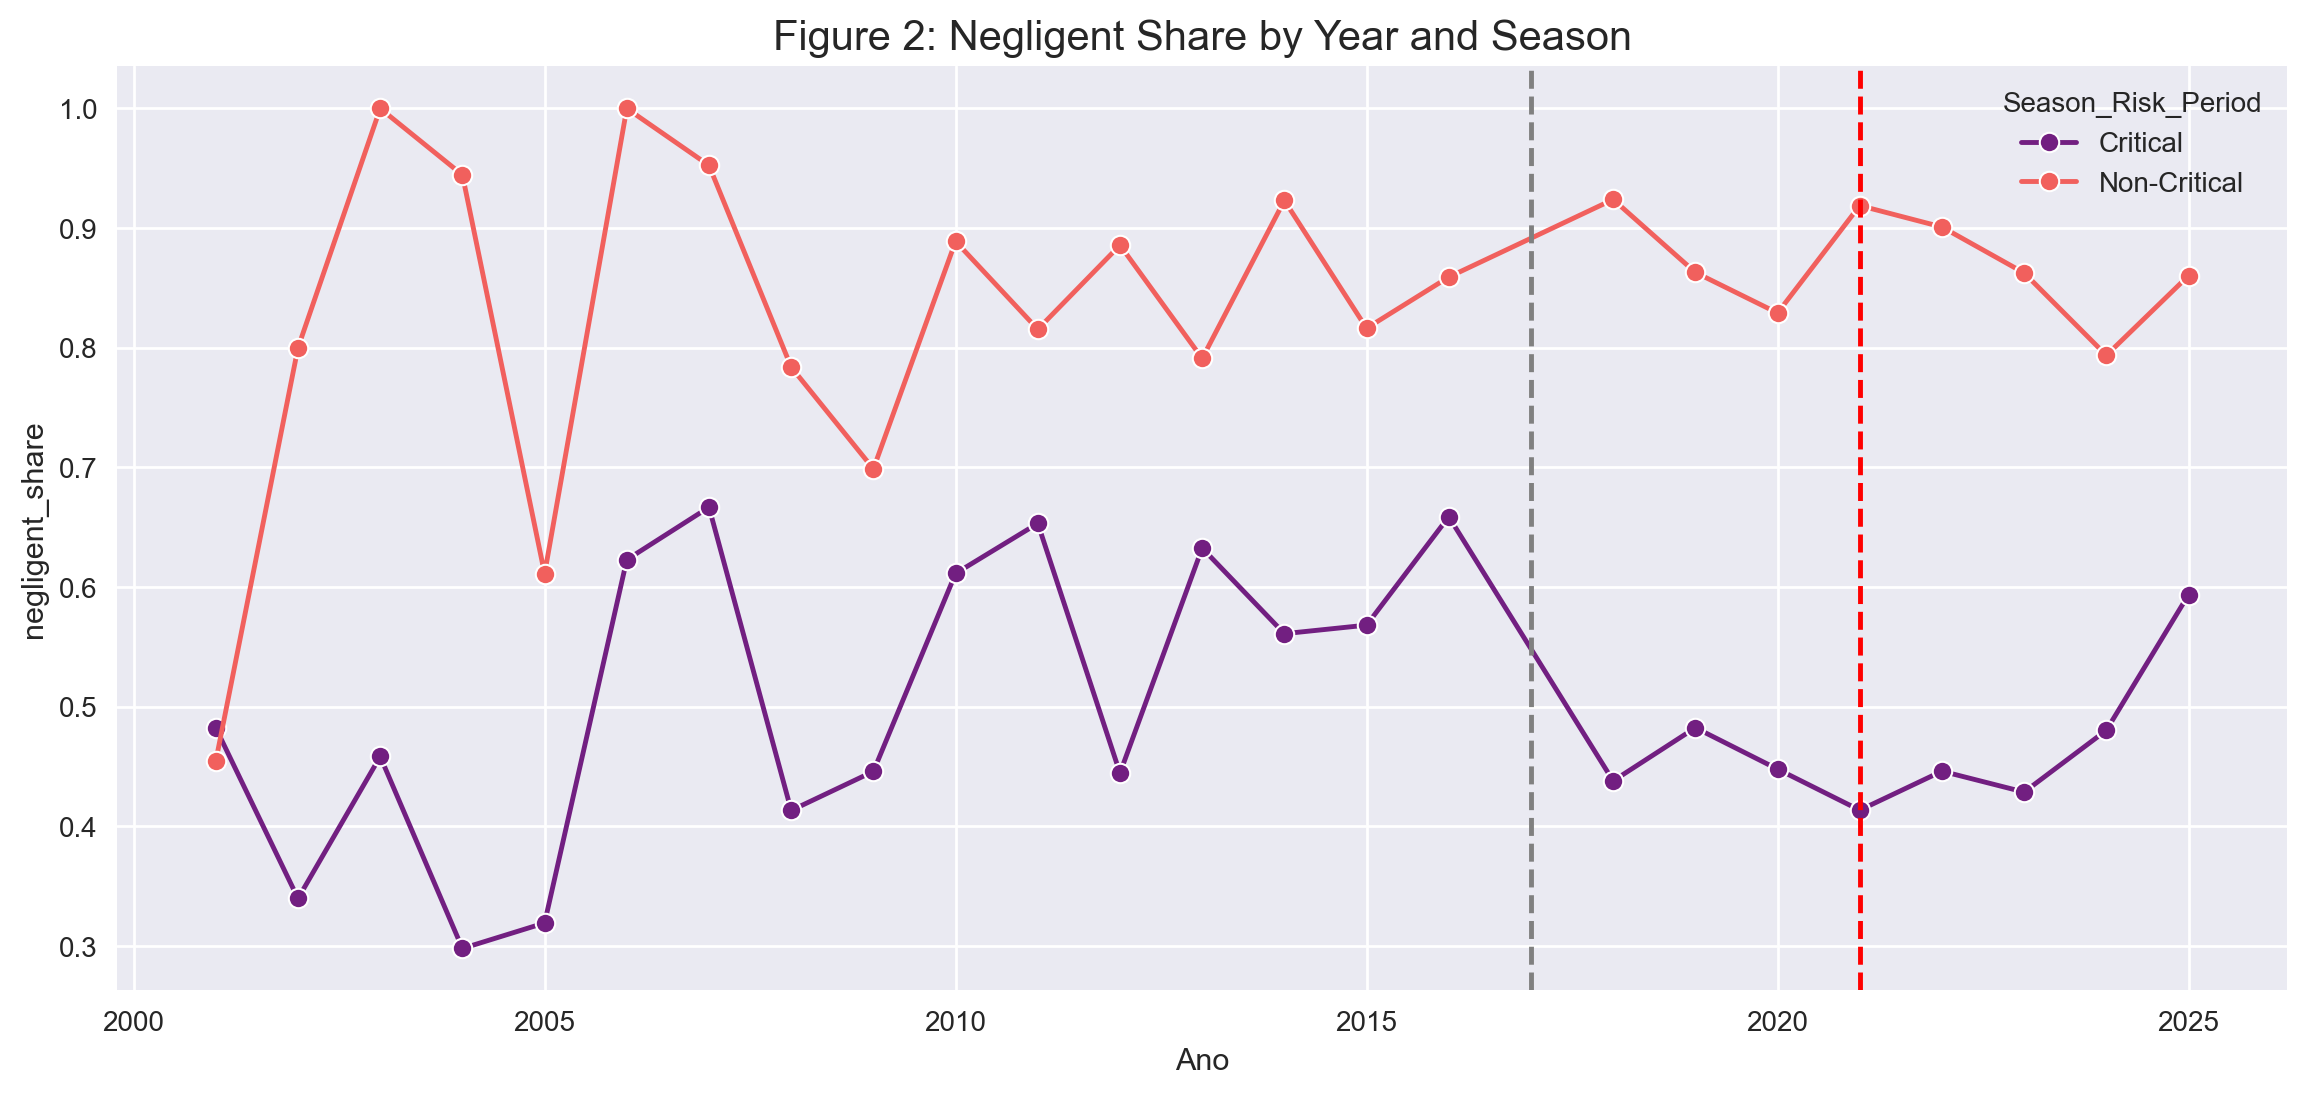

In [16]:
year_season = (
    q1.groupby(["Ano", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)

plt.figure(figsize=(14, 6))
sns.lineplot(data=year_season, x="Ano", y="negligent_share",
             hue="Season_Risk_Period", marker="o", palette="magma")
plt.axvline(2017, color="grey", linestyle="--")
plt.axvline(2021, color="red", linestyle="--")
plt.title("Figure 2: Negligent Share by Year and Season", fontsize=15)
plt.show()

#### Conclusions

To explore this question, we split the data into pre-2017 and post-2017 periods and compared the negligent share between critical and non-critical seasons. The visualisations and proportions showed a clear divergence between the seasons. In the critical period, the negligent share dropped from 55.7% to 47.4% after 2017. But, in the non-critical months, the share of negligent fires actually increased from 82.6% to 88.2%.

This means that the seasons do not behave in the same way, the reduction in negligent ignitions did not affect the whole year. It was entirely concentrated in the critical summer months.

Also, if the law implemented in 2021 actually deterred negligent ignitions, we would expect a sharp drop right after the red line in Figure 2. Instead, the non-critical line stays flat, and the critical line drops slightly in 2021 but climbs right back up by 2024/2025.

---

### Burnt Area by Cause Type and Period (Q4)

In this section we address Q4, which asks whether the gap in final burnt area between intentional and negligent fires became smaller after 2017 in the four municipalities under study.

A two-way ANOVA was chosen because the response variable (`Log_Total_Burnt_Area`) is quantitative and there are two qualitative factors with two levels each, `Cause_Type` (Intentional, Negligent) and `Period` (Pre-2017, Post-2017). This design gives four groups and allows us to test three things at once, the effect of the cause, the effect of the period and the interaction between them. The research question is answered by the interaction term. If the difference between causes is not the same in both periods, the interaction will be significant.

The burnt area is analysed on a log10 scale because it is extremely right-skewed, with most fires below 1 ha and a few above 1,000 ha. On this scale, the mean corresponds to the geometric mean, which describes the typical fire better than the arithmetic mean.

**Hypotheses** (significance level α = 0.05)

| Effect | H₀ | H₁ |
|---|---|---|
| Cause_Type | The mean log burnt area is the same for intentional and negligent fires | The means differ |
| Period | The mean log burnt area is the same before and after 2017 | The means differ |
| Interaction | The difference between causes is the same in both periods | The difference between causes changes from one period to the other |

#### Data 

In [37]:
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

q4 = pd.read_excel(processed / "q4_burnt_area_cause_period.xlsx")

# fixed order of the factor levels for tables and plots
period_order = ["Pre-2017", "Post-2017"]
cause_order = ["Intentional", "Negligent"]
q4["Period"] = pd.Categorical(q4["Period"], categories=period_order, ordered=True)
q4["Cause_Type"] = pd.Categorical(q4["Cause_Type"], categories=cause_order, ordered=True)

pd.crosstab(q4["Cause_Type"], q4["Period"], margins=True)

Period,Pre-2017,Post-2017,All
Cause_Type,,,
Intentional,1381,789,2170
Negligent,2653,1696,4349
All,4034,2485,6519


#### Descriptive statistics

In [38]:
q4_desc = (
    q4.groupby(["Period", "Cause_Type"], observed=True)
      .agg(n=("Log_Total_Burnt_Area", "size"),
           mean_log=("Log_Total_Burnt_Area", "mean"),
           sd_log=("Log_Total_Burnt_Area", "std"),
           median_ha=("Total_Burnt_Area", "median"),
           mean_ha=("Total_Burnt_Area", "mean"))
)
# geometric mean in hectares (back-transformation of the log mean)
q4_desc["geom_mean_ha"] = 10 ** q4_desc["mean_log"]
q4_desc.round(3)

n  mean_log  sd_log  median_ha  mean_ha  \
Period    Cause_Type                                                
Pre-2017  Intentional  1381    -0.553   1.228      0.260   24.761   
          Negligent    2653    -0.395   1.109      0.500    8.622   
Post-2017 Intentional   789    -0.934   1.195      0.085   23.227   
          Negligent    1696    -0.634   1.170      0.290    8.726   

                       geom_mean_ha  
Period    Cause_Type                 
Pre-2017  Intentional         0.280  
          Negligent           0.403  
Post-2017 Intentional         0.116  
          Negligent           0.232

The design is unbalanced (from 789 to 2,653 fires per group), but every group is large. The table also shows why the log scale is needed. Intentional fires have a much higher arithmetic mean (around 23 to 25 ha vs 9 ha), but a lower median (0.26 vs 0.50 ha before 2017), because a few very large intentional fires inflate the mean. The geometric means agree with the medians.

#### Distribution of burnt area by group

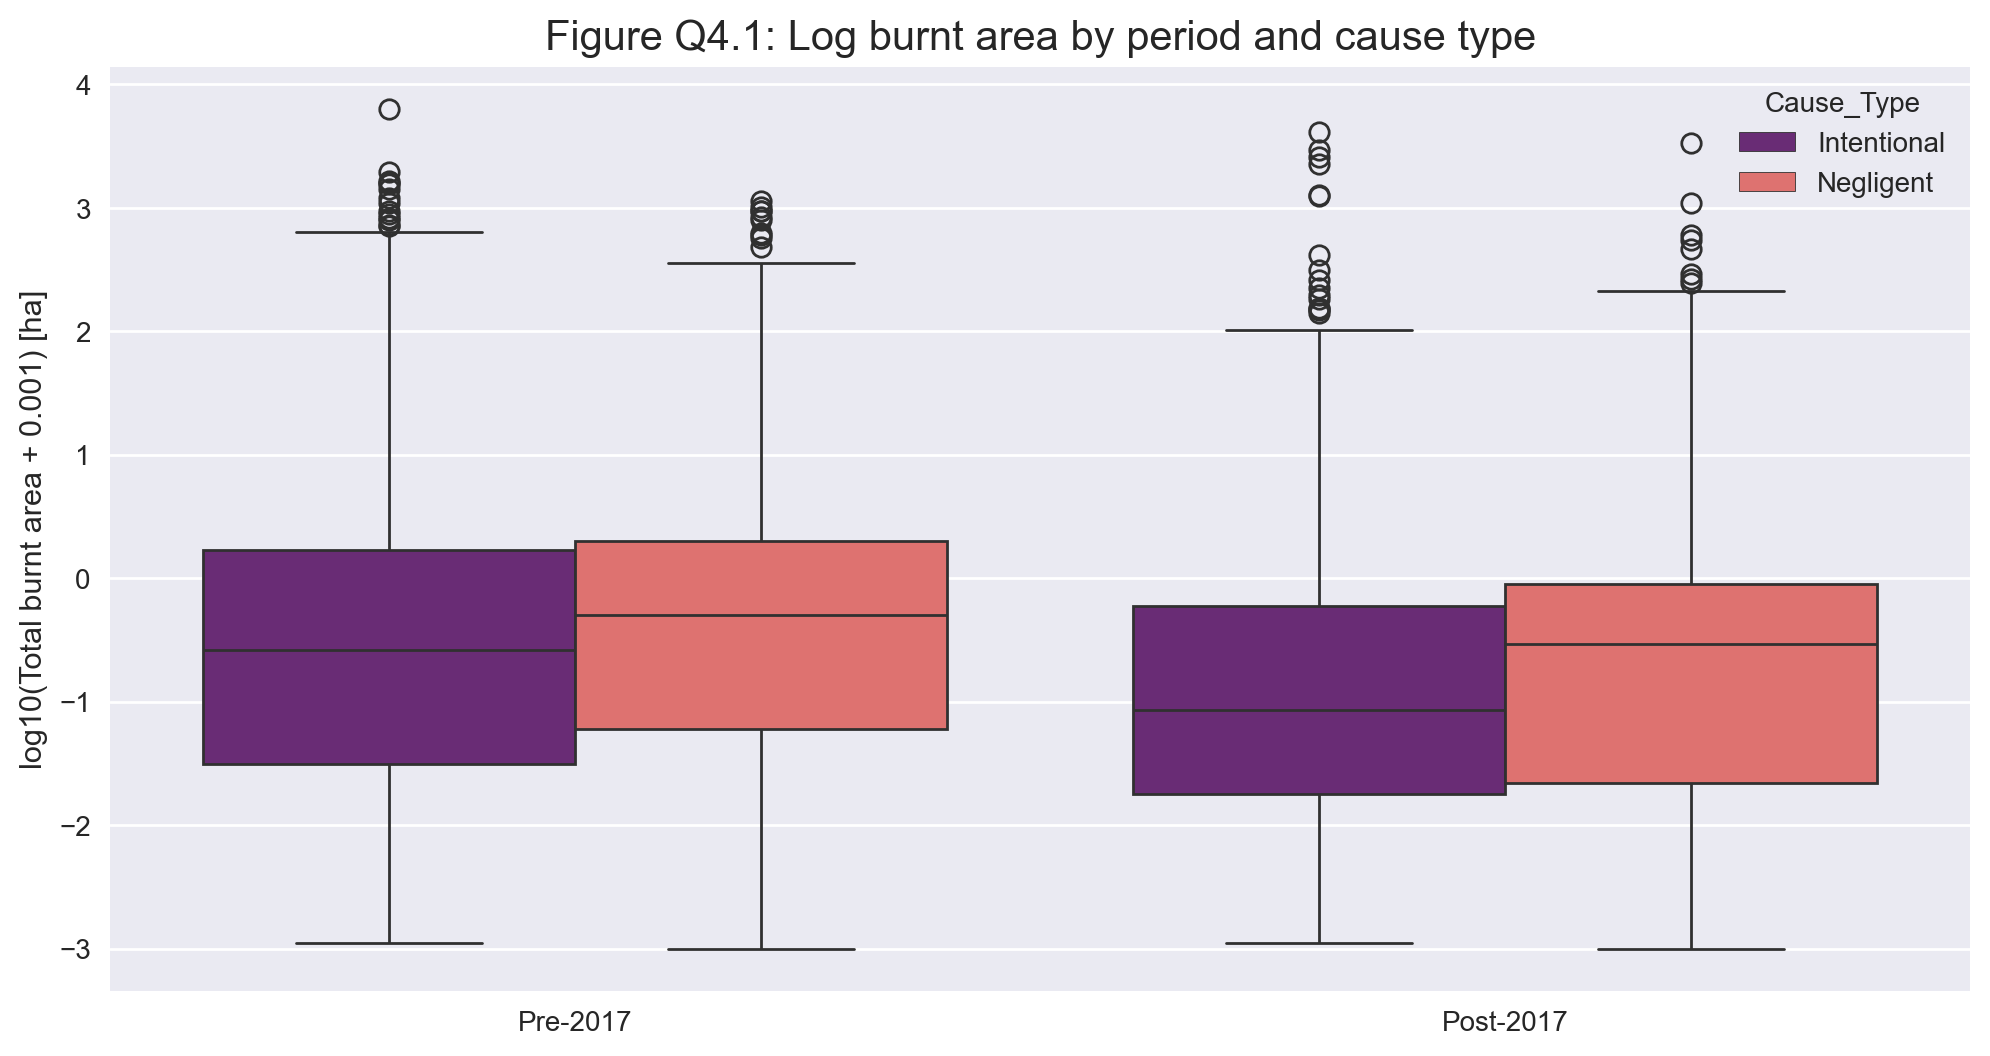

In [39]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
            order=period_order, hue_order=cause_order, palette="magma", ax=ax)
ax.set_title("Figure Q4.1: Log burnt area by period and cause type", fontsize=15)
ax.set_ylabel("log10(Total burnt area + 0.001) [ha]")
ax.set_xlabel("")
plt.show()

In [40]:
# Numbers behind Figure Q4.1 (boxplot statistics on the log scale)
box_rows = []
for (cause, period), g in q4.groupby(["Cause_Type", "Period"], observed=True):
    x = g["Log_Total_Burnt_Area"]
    area = g["Total_Burnt_Area"]
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    box_rows.append({
        "Cause_Type": cause,
        "Period": period,
        "min": x.min(),
        "lower_whisker": x[x >= q1 - 1.5 * iqr].min(),
        "Q1": q1,
        "median": med,
        "Q3": q3,
        "upper_whisker": x[x <= q3 + 1.5 * iqr].max(),
        "max": x.max(),
        "n_outliers_upper": (x > q3 + 1.5 * iqr).sum(),
        "n_outliers_lower": (x < q1 - 1.5 * iqr).sum(),
        "n_0_ha": (area == 0).sum(),
        "n_0.01_ha": (area == 0.01).sum(),
    })
pd.DataFrame(box_rows).round(3)

,Cause_Type,Period,min,lower_whisker,Q1,median,Q3,upper_whisker,max,n_outliers_upper,n_outliers_lower,n_0_ha,n_0.01_ha
0,Intentional,Pre-2017,-2.959,-2.959,-1.509,-0.583,0.231,2.801,3.805,14,0,0,76
1,Intentional,Post-2017,-2.959,-2.959,-1.745,-1.066,-0.221,2.008,3.618,16,0,0,32
2,Negligent,Pre-2017,-3.000,-3.000,-1.223,-0.300,0.301,2.556,3.060,10,0,2,268
3,Negligent,Post-2017,-3.000,-3.000,-1.658,-0.536,-0.045,2.324,3.527,8,0,1,229


In [41]:
# Most frequent burnt area values (in ha)
q4["Total_Burnt_Area"].value_counts().head(6)

Total_Burnt_Area
0.01    605
0.50    442
1.00    375
2.00    227
0.10    193
1.50    166
Name: count, dtype: int64

Figure Q4.1 shows that the four distributions overlap heavily, as expected for a variable with high natural variability. Even so, the median of negligent fires is higher than that of intentional fires in both periods (-0.30 vs -0.58 before 2017 and -0.54 vs -1.07 after 2017), and all medians are lower after 2017. The lower whiskers reach about -3 because of very small fires (0.0001 ha or 0 ha). Areas are often recorded as rounded values, and 0.01 ha is the most frequent value (605 fires).

#### Interaction plot 

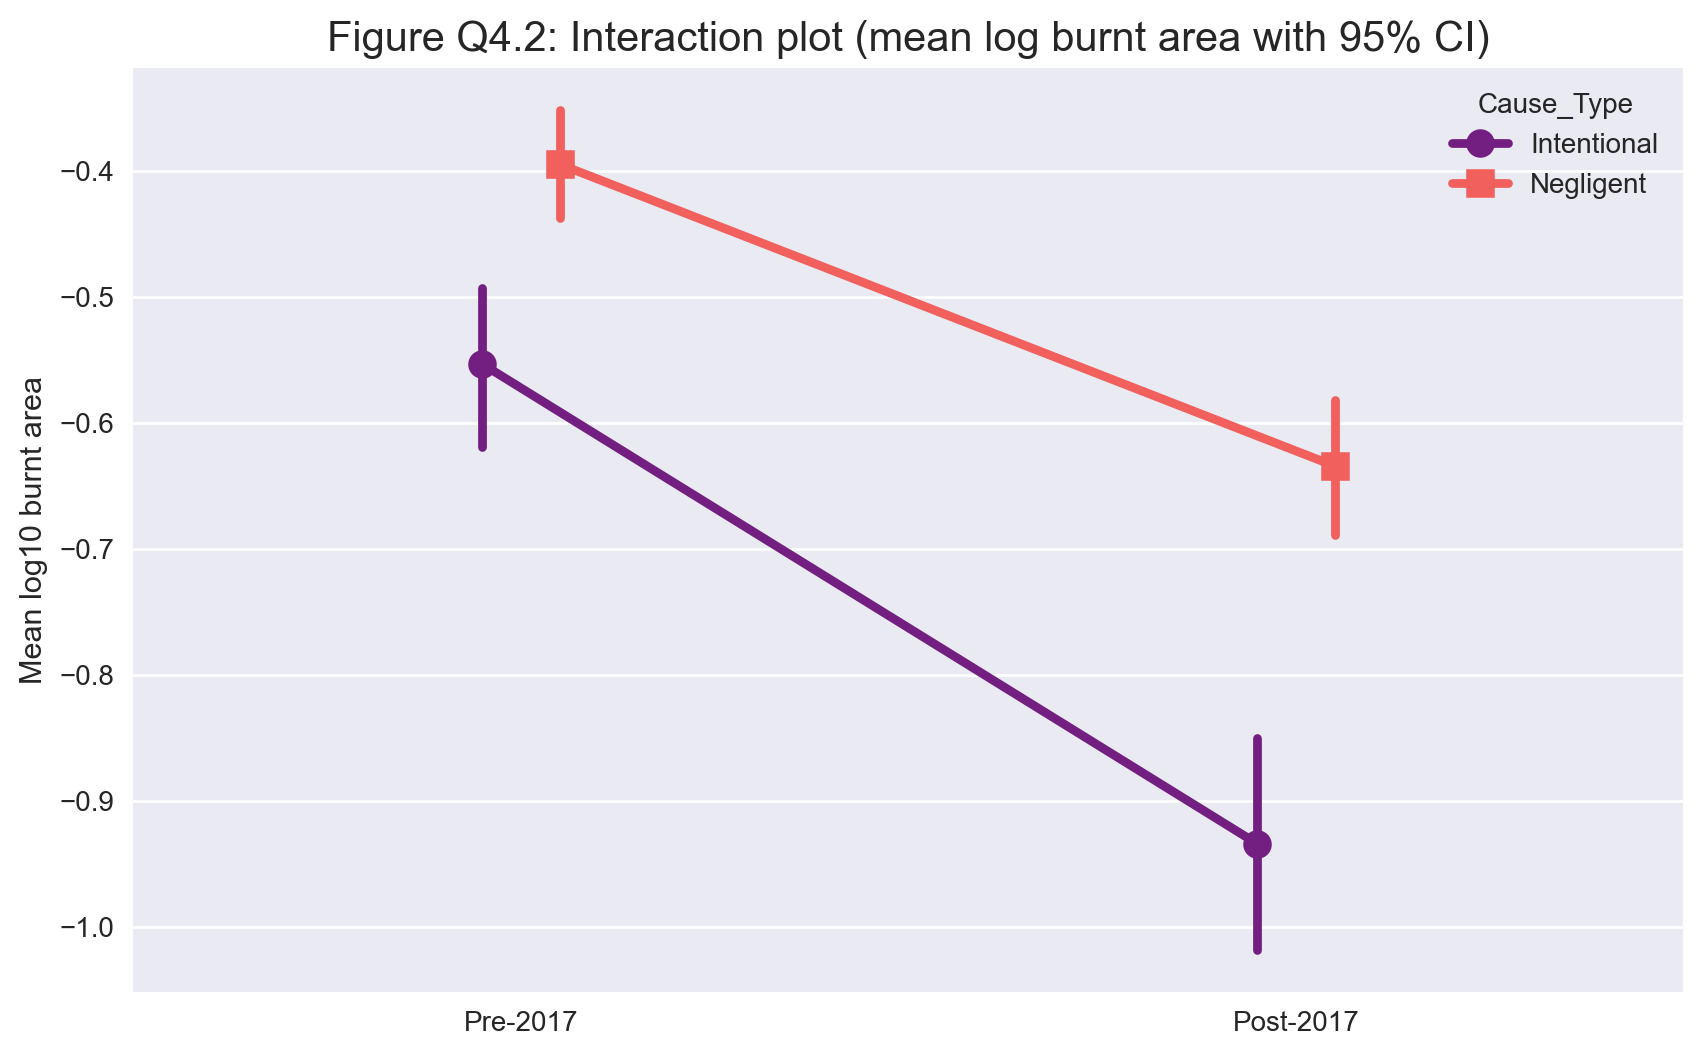

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.pointplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
              order=period_order, hue_order=cause_order, palette="magma",
              errorbar=("ci", 95), dodge=0.1, markers=["o", "s"], ax=ax)
ax.set_title("Figure Q4.2: Interaction plot (mean log burnt area with 95% CI)", fontsize=15)
ax.set_ylabel("Mean log10 burnt area")
ax.set_xlabel("")
plt.show()

In [43]:
# Numbers behind Figure Q4.2
q4_means = (
    q4.groupby(["Period", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
      .agg(n="size", mean="mean", sd="std")
)
q4_means["se"] = q4_means["sd"] / np.sqrt(q4_means["n"])
t_crit = stats.t.ppf(0.975, q4_means["n"] - 1)
q4_means["ci_low"] = q4_means["mean"] - t_crit * q4_means["se"]
q4_means["ci_high"] = q4_means["mean"] + t_crit * q4_means["se"]
display(q4_means.round(3))

m = q4_means["mean"].unstack()
drop = m.loc["Pre-2017"] - m.loc["Post-2017"]
gap = m["Negligent"] - m["Intentional"]
print("Drop after 2017 (log units):")
print(drop.round(3))
print("\nGap Negligent - Intentional (log units):")
print(gap.round(3))
print(f"\nChange in the gap: {gap['Post-2017'] - gap['Pre-2017']:.3f}")

# 95% CI for the change in the gap (interaction coefficient)
model_int = smf.ols("Log_Total_Burnt_Area ~ C(Cause_Type) * C(Period)", data=q4).fit()
int_name = [p for p in model_int.params.index if ":" in p][0]
ci = model_int.conf_int().loc[int_name]
print(f"Interaction coefficient: {model_int.params[int_name]:.3f}, "
      f"95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")

n   mean     sd     se  ci_low  ci_high
Period    Cause_Type                                             
Pre-2017  Intentional  1381 -0.553  1.228  0.033  -0.618   -0.488
          Negligent    2653 -0.395  1.109  0.022  -0.437   -0.352
Post-2017 Intentional   789 -0.934  1.195  0.043  -1.018   -0.851
          Negligent    1696 -0.634  1.170  0.028  -0.690   -0.579

Drop after 2017 (log units):
Cause_Type
Intentional    0.381
Negligent      0.240
dtype: float64

Gap Negligent - Intentional (log units):
Period
Pre-2017     0.159
Post-2017    0.300
dtype: float64

Change in the gap: 0.141
Interaction coefficient: 0.141, 95% CI [0.017, 0.265]


The Figure Q4.2 is the most direct visual answer to the research question. If the gap between causes had narrowed after 2017, the two lines would converge. Instead, they move slightly apart. The mean for intentional fires drops by 0.38 log units (from -0.55 to -0.93), while the mean for negligent fires drops by 0.24 (from -0.39 to -0.63). As a result, the gap between causes goes from 0.16 to 0.30 log units, an increase of 0.14. The 95% confidence interval for this increase (0.02 to 0.27) does not include zero, but its lower limit is close to it, which suggests a real but small change.

#### Checking the assumptions

ANOVA requires three conditions. The observations must be independent, the data within each group must be approximately normal, and the variability must be similar across groups.

Independence is reasonable because each row corresponds to a different fire. The other two conditions are checked below for each of the four Cause_Type x Period groups, using histograms and normal probability plots (Q-Q plots) for normality and comparing the standard deviations of the groups for constant variance.

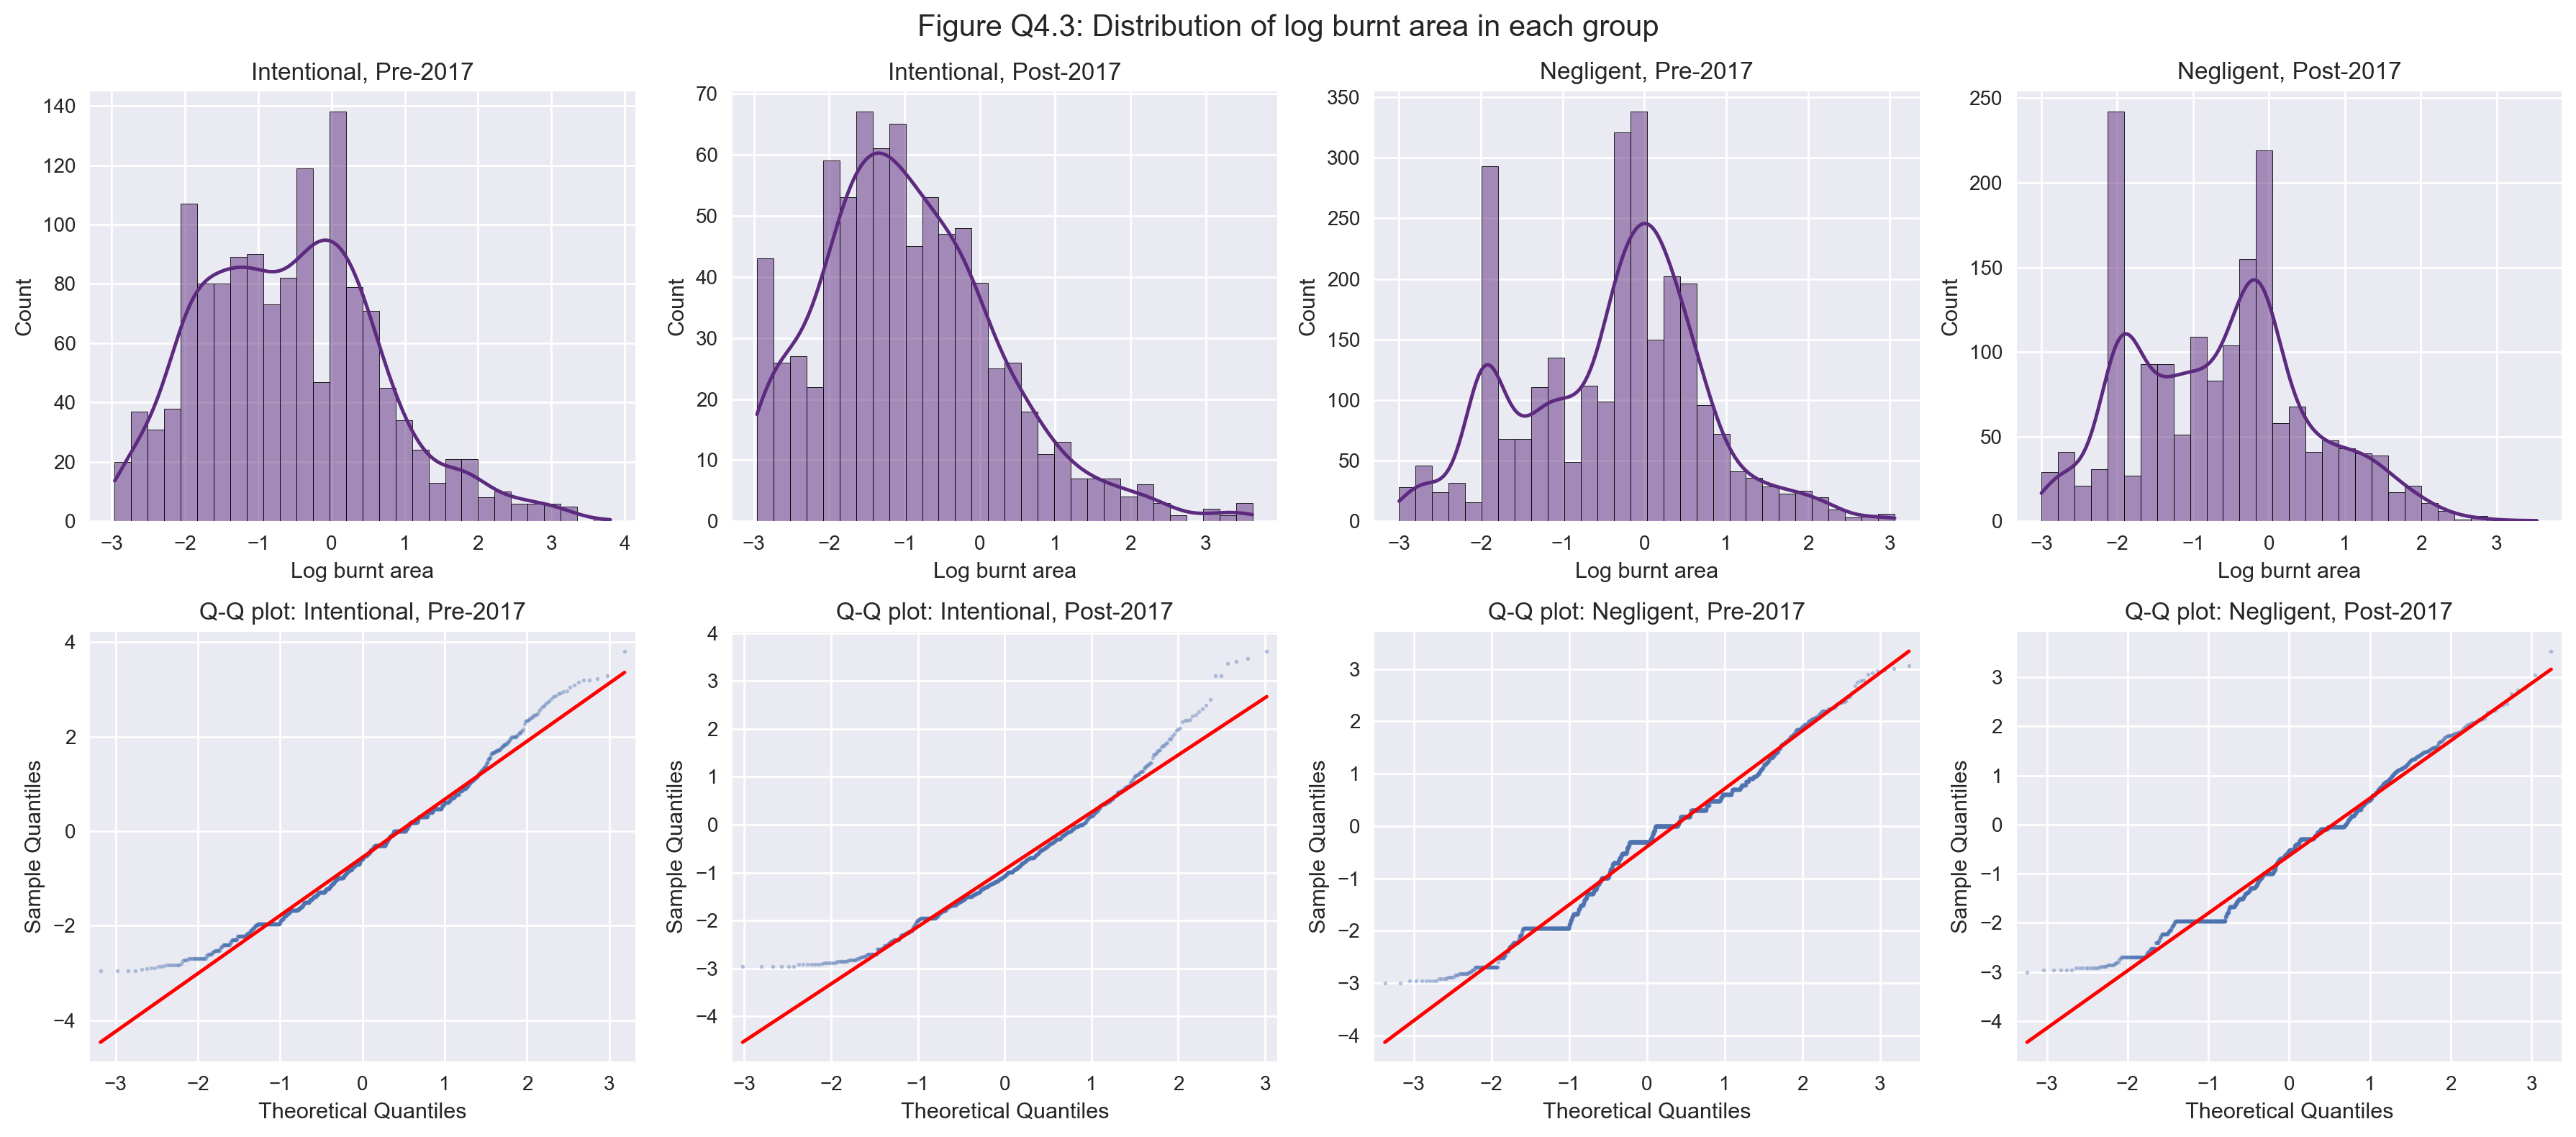

    Cause_Type     Period  Log_Total_Burnt_Area
0  Intentional   Pre-2017                 1.228
1  Intentional  Post-2017                 1.195
2    Negligent   Pre-2017                 1.109
3    Negligent  Post-2017                 1.170

Largest SD / smallest SD: 1.11
Levene test: W = 11.00, p = 3.33e-07


In [44]:
# Normality within each group
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, ((cause, period), g) in enumerate(q4.groupby(["Cause_Type", "Period"], observed=True)):
    x = g["Log_Total_Burnt_Area"]
    sns.histplot(x, bins=30, kde=True, color="#5c2a7e", ax=axes[0, i])
    axes[0, i].set_title(f"{cause}, {period}")
    axes[0, i].set_xlabel("Log burnt area")
    sm.qqplot(x, line="s", ax=axes[1, i], markersize=2, alpha=0.4)
    axes[1, i].set_title(f"Q-Q plot: {cause}, {period}")
fig.suptitle("Figure Q4.3: Distribution of log burnt area in each group", fontsize=15)
plt.tight_layout()
plt.show()

# Constant variance: standard deviation of each group
sd_q4 = q4.groupby(["Cause_Type", "Period"], observed=True)["Log_Total_Burnt_Area"].std()
print(sd_q4.round(3).reset_index())
print(f"\nLargest SD / smallest SD: {sd_q4.max() / sd_q4.min():.2f}")

# Complementary test for equal variances (Levene, median-centred)
groups_q4 = [g["Log_Total_Burnt_Area"].values
             for _, g in q4.groupby(["Cause_Type", "Period"], observed=True)]
lev = stats.levene(*groups_q4, center="median")
print(f"Levene test: W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

**Normality.** On the log scale, the distributions are much closer to symmetric than the original data, but they are not normal. The intentional groups have a longer right tail, which corresponds to a small number of very large fires. The negligent groups show two peaks (at about -2 and 0) caused by the many fires recorded with exactly 0.01 ha and 1 ha. These peaks reflect the rounding of the recorded areas and also explain the horizontal steps in the Q-Q plots. There are no extreme outliers. Since ANOVA compares means and every group has at least 789 observations, the sampling distribution of each mean is approximately normal by the Central Limit Theorem, so this departure is not a concern. Robustness checks that do not rely on this assumption are presented together with the ANOVA results.

**Constant variance.** The standard deviations range from 1.11 to 1.23, and the largest is only 1.11 times the smallest(ratio 1.11), so the variability is very similar across groups. The Levene test rejects equal variances (p < 0.001), but with more than 6,500 observations it detects differences too small to matter in practice. The condition of constant variance is considered satisfied.

#### Two-way ANOVA

The model includes the two main effects (Cause_Type and Period) and their interaction. Because the groups have different sizes, Type III sums of squares are used, so that each effect is tested after accounting for the others. Sum-to-zero coding is used so that each main effect is tested as an average across the levels of the other factor.

The effect size of each term is measured with partial eta squared (partial η²), which is the proportion of variability explained by the effect after removing the variability explained by the other effects. The usual reference values are 0.01 (small), 0.06 (medium) and 0.14 (large).

In [45]:
model_q4 = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4
).fit()

anova_q4 = sm.stats.anova_lm(model_q4, typ=3)
ss_res = anova_q4.loc["Residual", "sum_sq"]
anova_q4["partial_eta_sq"] = anova_q4["sum_sq"] / (anova_q4["sum_sq"] + ss_res)
anova_q4.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4.round(4)

,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2140.5659,1.0,1587.4279,0.0000,NaN
Cause_Type,71.0569,1.0,52.6953,0.0000,0.0080
Period,130.1719,1.0,96.5346,0.0000,0.0146
Cause_Type x Period,6.7470,1.0,5.0036,0.0253,0.0008
Residual,8785.1466,6515.0,NaN,NaN,NaN


To check that the conclusions do not depend on the assumptions that were not fully met, the analysis is repeated in two ways. The first is an ANOVA with heteroscedasticity-consistent standard errors (HC3), which does not assume equal variances. The second is a non-parametric Kruskal-Wallis test applied to the four groups, which does not assume normality.

In [46]:
# Robustness check 1: ANOVA with heteroscedasticity-consistent errors (HC3)
anova_q4_hc3 = sm.stats.anova_lm(model_q4, typ=3, robust="hc3")
anova_q4_hc3.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(anova_q4_hc3[["F", "PR(>F)"]].round(4))

# Robustness check 2: Kruskal-Wallis across the four Cause_Type x Period groups
kw = stats.kruskal(*groups_q4)
print(f"\nKruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.2e}")

                             F  PR(>F)
Intercept            1516.7840  0.0000
Cause_Type             50.3503  0.0000
Period                 92.2386  0.0000
Cause_Type x Period     4.7809  0.0288
Residual                   NaN     NaN

Kruskal-Wallis: H = 181.03, p = 5.29e-39


All three effects are significant at α = 0.05.

- **Cause_Type** (F(1, 6515) = 52.70, p < 0.001). Negligent fires have a larger typical burnt area.
- **Period** (F(1, 6515) = 96.53, p < 0.001). The mean log burnt area is lower after 2017.
- **Interaction** (F(1, 6515) = 5.00, p = 0.025). The difference between causes changes between periods.

The HC3 version gives the same conclusions (interaction p = 0.029), and the Kruskal-Wallis test confirms that the four groups differ (p < 0.001), although it cannot test the interaction separately.

The effect sizes are small. Only Period reaches a small effect (partial η² = 0.015), Cause_Type is below this threshold (0.008) and the interaction is negligible (0.0008). The interaction is statistically significant because the large sample can detect very small differences, but its practical relevance is very limited. In other words, the difference between causes did change between periods, but by an amount that is small compared with the natural variation in burnt area from fire to fire.

#### Post-hoc analysis

Since the interaction is significant, the main effects alone do not fully describe the results. The analysis is therefore completed in two steps. First, the two causes are compared within each period (simple effects), which shows how the difference between causes behaves before and after 2017. Second, all four groups are compared pairwise, which shows how each cause changed between periods.

In [47]:
# Simple effects: Negligent vs Intentional within each period (Welch t-test)
rows = []
for p in period_order:
    sub = q4[q4["Period"] == p]
    neg = sub.loc[sub["Cause_Type"] == "Negligent", "Log_Total_Burnt_Area"]
    inten = sub.loc[sub["Cause_Type"] == "Intentional", "Log_Total_Burnt_Area"]
    t = stats.ttest_ind(neg, inten, equal_var=False)
    diff = neg.mean() - inten.mean()
    rows.append({"Period": p, "diff_log (Neg - Int)": diff,
                 "ratio_geom_means": 10 ** diff, "t": t.statistic, "p_value": t.pvalue})
pd.DataFrame(rows).round(4)

,Period,diff_log (Neg - Int),ratio_geom_means,t,p_value
0,Pre-2017,0.1586,1.4408,4.0218,0.0001
1,Post-2017,0.2999,1.9947,5.8631,0.0000


In both periods, negligent fires have a significantly larger mean log burnt area (Bonferroni α = 0.025, both p < 0.001). The typical negligent fire was about 1.4 times larger than the intentional one before 2017 and about 2.0 times larger after.

In [48]:
# Pairwise comparisons with Bonferroni correction (OpenIntro, section 7.5)
from itertools import combinations

group_stats = q4.groupby("Cause_Type_Period")["Log_Total_Burnt_Area"].agg(["size", "mean"])
mse = model_q4.mse_resid          # pooled variance from the ANOVA
df_resid = model_q4.df_resid      # 6515
K = 6                             # number of pairwise comparisons
alpha_bonf = 0.05 / K

pairs = []
for g1, g2 in combinations(group_stats.index, 2):
    n1, m1 = group_stats.loc[g1]
    n2, m2 = group_stats.loc[g2]
    diff = m1 - m2
    se = np.sqrt(mse / n1 + mse / n2)
    t_stat = diff / se
    p_val = 2 * stats.t.sf(abs(t_stat), df_resid)
    pairs.append({"group1": g1, "group2": g2, "diff": diff, "t": t_stat,
                  "p_value": p_val, "significant": p_val < alpha_bonf})

print(f"Bonferroni significance level: 0.05 / {K} = {alpha_bonf:.4f}")
pd.DataFrame(pairs).round(4)

Bonferroni significance level: 0.05 / 6 = 0.0083


,group1,group2,diff,t,p_value,significant
0,Intentional_Post-2017,Intentional_Pre-2017,-0.3809,-7.3503,0.0000,True
1,Intentional_Post-2017,Negligent_Post-2017,-0.2999,-5.9925,0.0000,True
2,Intentional_Post-2017,Negligent_Pre-2017,-0.5395,-11.4571,0.0000,True
3,Intentional_Pre-2017,Negligent_Post-2017,0.0810,1.9252,0.0542,False
4,Intentional_Pre-2017,Negligent_Pre-2017,-0.1586,-4.1160,0.0000,True
5,Negligent_Post-2017,Negligent_Pre-2017,-0.2396,-6.6376,0.0000,True


Six pairwise comparisons were performed using the pooled standard deviation from the ANOVA and a Bonferroni-corrected significance level of 0.05 / 6 ≈ 0.0083. Five of the six pairs differ significantly. The only exception is intentional fires before 2017 vs negligent fires after 2017 (p = 0.054). Both causes decreased after 2017, but intentional fires decreased more, which moved the two causes further apart.

#### Robustness check: controlling for municipality

The four municipalities differ in typical fire size. Fires in Montalegre and Chaves are larger (geometric means of 0.68 ha and 0.36 ha), while fires in Ourém and Tomar are much smaller (0.08 ha and 0.09 ha). The municipalities also do not contribute equally to each group. Ourém accounts for 46% of intentional fires after 2017, compared with 26% before, while Montalegre accounts for more than half of all negligent fires. A change in the mix of municipalities could therefore create an apparent interaction. To check this, Municipality (`Concelho`) was added to the model as a blocking factor.

In [49]:
# Typical burnt area in each municipality
mun_q4 = q4.groupby("Concelho").agg(
    n=("Log_Total_Burnt_Area", "size"),
    mean_log=("Log_Total_Burnt_Area", "mean"),
    median_ha=("Total_Burnt_Area", "median"),
)
mun_q4["geom_mean_ha"] = 10 ** mun_q4["mean_log"]
mun_q4.sort_values("mean_log", ascending=False).round(3)

,n,mean_log,median_ha,geom_mean_ha
Concelho,,,,
Montalegre,2684,-0.168,0.950,0.679
Chaves,1501,-0.445,0.500,0.359
Tomar,1134,-1.055,0.076,0.088
Ourém,1200,-1.090,0.064,0.081


In [50]:
pd.crosstab(q4["Cause_Type_Period"], q4["Concelho"], normalize="index").round(2)

Concelho,Chaves,Montalegre,Ourém,Tomar
Cause_Type_Period,,,,
Intentional_Post-2017,0.18,0.11,0.46,0.25
Intentional_Pre-2017,0.29,0.15,0.26,0.31
Negligent_Post-2017,0.20,0.57,0.11,0.12
Negligent_Pre-2017,0.23,0.54,0.11,0.12


In [51]:
model_q4_mun = smf.ols(
    "Log_Total_Burnt_Area ~ C(Concelho, Sum) + C(Cause_Type, Sum) * C(Period, Sum)",
    data=q4
).fit()
anova_q4_mun = sm.stats.anova_lm(model_q4_mun, typ=3)
anova_q4_mun.index = ["Intercept", "Municipality", "Cause_Type", "Period",
                      "Cause_Type x Period", "Residual"]
anova_q4_mun.round(4)

,sum_sq,df,F,PR(>F)
Intercept,2574.3631,1.0,2153.2091,0.0000
Municipality,999.4406,3.0,278.6456,0.0000
Cause_Type,35.2700,1.0,29.5000,0.0000
Period,90.8401,1.0,75.9791,0.0000
Cause_Type x Period,0.2044,1.0,0.1710,0.6793
Residual,7785.7060,6512.0,NaN,NaN


With municipality in the model, cause type and period remain significant (p < 0.001), but the interaction does not (F = 0.17, p = 0.68). The wider gap after 2017 can therefore be explained by a change in where fires occurred, mainly the larger share of intentional fires in Ourém, and not necessarily by a change in the relationship between cause and fire size.

#### Conclusions

The disparity in final burnt area between intentional and negligent fires did not narrow after 2017. The typical negligent fire was larger than the typical intentional fire in both periods, and the gap went from a ratio of about 1.4 to about 2.0. The two-way ANOVA found a significant interaction (p = 0.025), but with a negligible effect size, and this interaction is no longer significant when municipality is included in the model.

The most consistent result is the effect of the period, since fires of both causes became smaller after 2017. This effect holds in every version of the analysis. The cause type also has a stable effect, with negligent fires burning more area in a typical case, although intentional fires include the largest events, as shown by their much higher arithmetic mean.

For the four municipalities studied, there is no consistent evidence that the change between periods differed between the two causes. The reduction in fire size after 2017 was shared by both. Since this is an observational study, and the post-2017 period mixes years before and after the 2021 law, this reduction cannot be attributed to specific policy measures.

---

## 5) Look back and ahead

### Limitations of the Dataset

Two limitations affect interpretation and should be kept in mind when reading the results.

First, the Period split is set at 2017, but the law was only implemented in 2021. The post-2017 group therefore mixes years before and after the law took effect, so any change attributed to the post-2017 period cannot be separated from the effect of the law itself without a further split.

Second, Initial_Response_Time and Fire_Duration depend on how consistently timestamps are recorded across municipalities. The alert source (FonteAlerta) also varies, and response time depends partly on who reported the fire. These differences may introduce variation between municipalities that is not caused by fire behaviour, which is relevant to the municipality comparison in Q4.